In [1]:
import os, random, copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
from pathlib import Path

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
OUT = Path('/content/cgan_results' if Path('/content').exists() else './cgan_results')
OUT.mkdir(parents=True, exist_ok=True)


Device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 511kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.45MB/s]


Training: 60000 Test: 10000 Batch: torch.Size([128, 1, 28, 28])


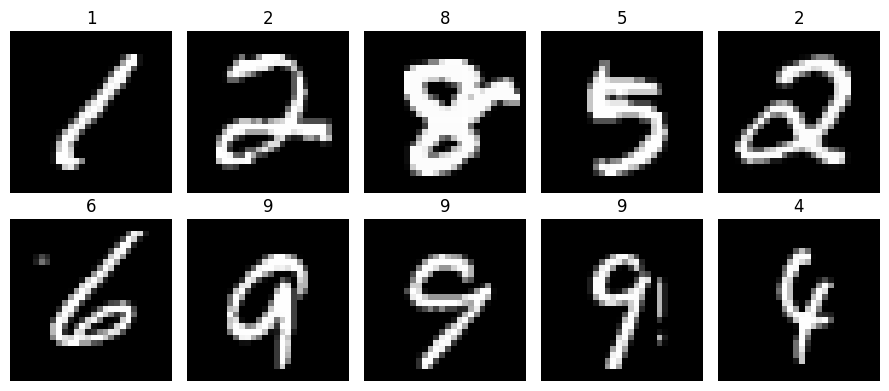

In [2]:
BATCH_SIZE = 128
train_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_set = datasets.MNIST(root='./data', train=True, download=True, transform=train_tf)
test_set = datasets.MNIST(root='./data', train=False, download=True, transform=train_tf)
loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=(device.type=='cuda'))
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)
images, labels = next(iter(loader))
print('Training:',len(train_set),'Test:',len(test_set),'Batch:',images.shape)
fig,ax=plt.subplots(2,5,figsize=(9,4))
for i,a in enumerate(ax.flat): a.imshow(images[i,0]*0.5+0.5,cmap='gray');a.set_title(str(labels[i].item()));a.axis('off')
plt.tight_layout();plt.show()


In [3]:
Z_DIM = 100
NUM_CLASSES = 10
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = nn.Embedding(NUM_CLASSES, 32)
        self.fc = nn.Sequential(nn.Linear(Z_DIM+32, 128*7*7), nn.BatchNorm1d(128*7*7), nn.ReLU(True))
        self.net = nn.Sequential(
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128,64,3,padding=1),nn.BatchNorm2d(64),nn.ReLU(True),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(64,32,3,padding=1),nn.BatchNorm2d(32),nn.ReLU(True),
            nn.Conv2d(32,1,3,padding=1),nn.Tanh())
    def forward(self,z,y):
        h=torch.cat([z,self.embed(y)],dim=1)
        return self.net(self.fc(h).reshape(-1,128,7,7))

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed=nn.Embedding(NUM_CLASSES,28*28)
        self.net=nn.Sequential(
            nn.Conv2d(2,32,4,2,1),nn.LeakyReLU(0.2,True),
            nn.Conv2d(32,64,4,2,1),nn.LeakyReLU(0.2,True),
            nn.Flatten(),nn.Linear(64*7*7,1))
    def forward(self,x,y):
        cond=self.embed(y).reshape(-1,1,28,28)
        return self.net(torch.cat([x,cond],dim=1)).flatten()

G=Generator().to(device); D=Discriminator().to(device)
print('Generator parameters:',sum(p.numel() for p in G.parameters()))
print('Discriminator parameters:',sum(p.numel() for p in D.parameters()))


Generator parameters: 939777
Discriminator parameters: 44865


Epoch 01/12 | G loss 0.7442 | D loss 0.6534


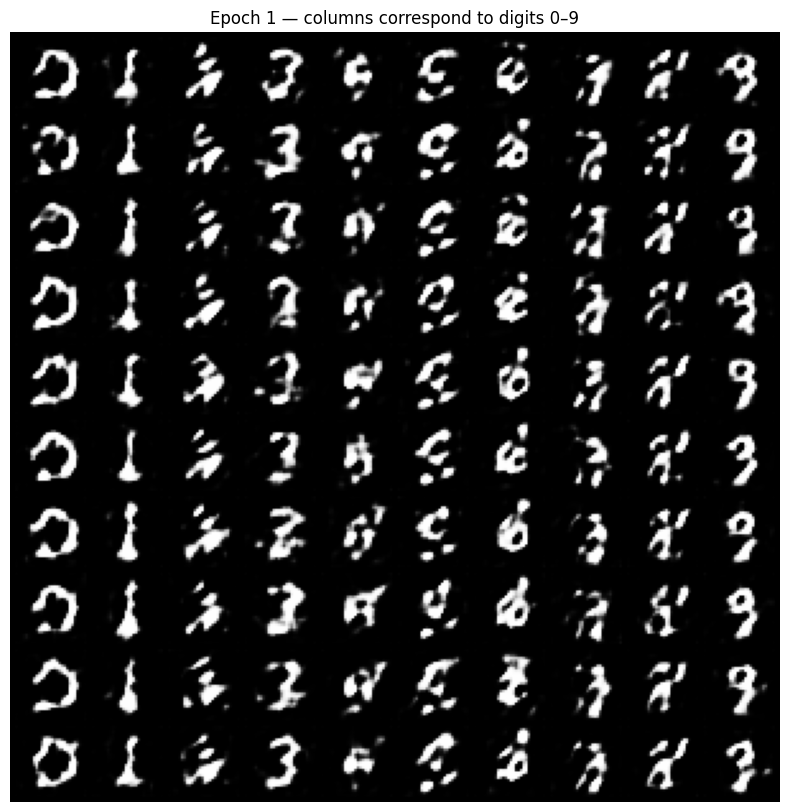

Epoch 02/12 | G loss 0.7220 | D loss 0.6824
Epoch 03/12 | G loss 0.7324 | D loss 0.6788
Epoch 04/12 | G loss 0.7504 | D loss 0.6709
Epoch 05/12 | G loss 0.7624 | D loss 0.6656


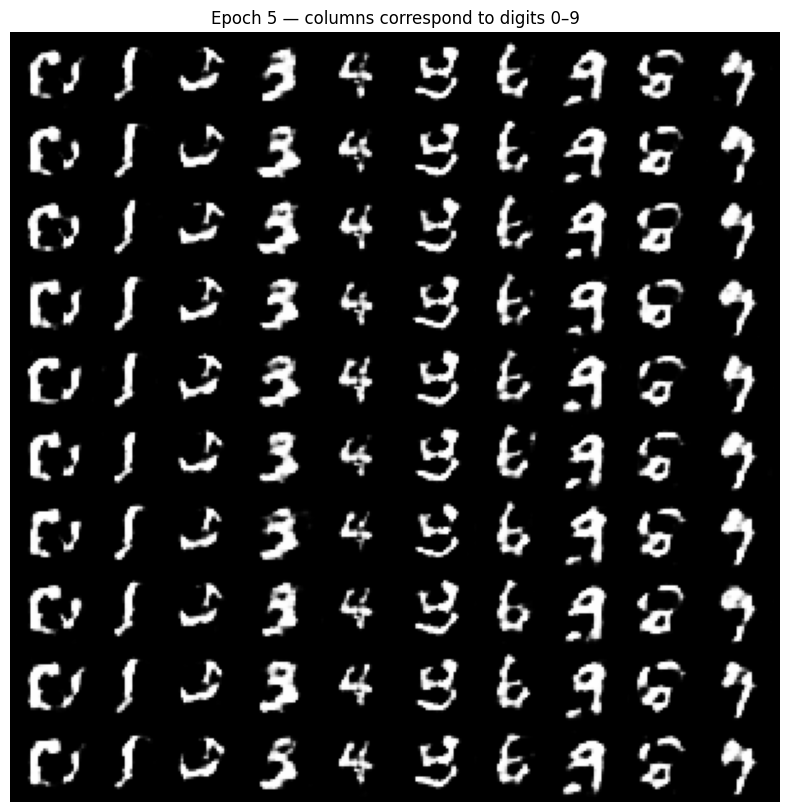

Epoch 06/12 | G loss 0.7695 | D loss 0.6665
Epoch 07/12 | G loss 0.7977 | D loss 0.6524
Epoch 08/12 | G loss 0.7996 | D loss 0.6541
Epoch 09/12 | G loss 0.8145 | D loss 0.6504
Epoch 10/12 | G loss 0.8148 | D loss 0.6526


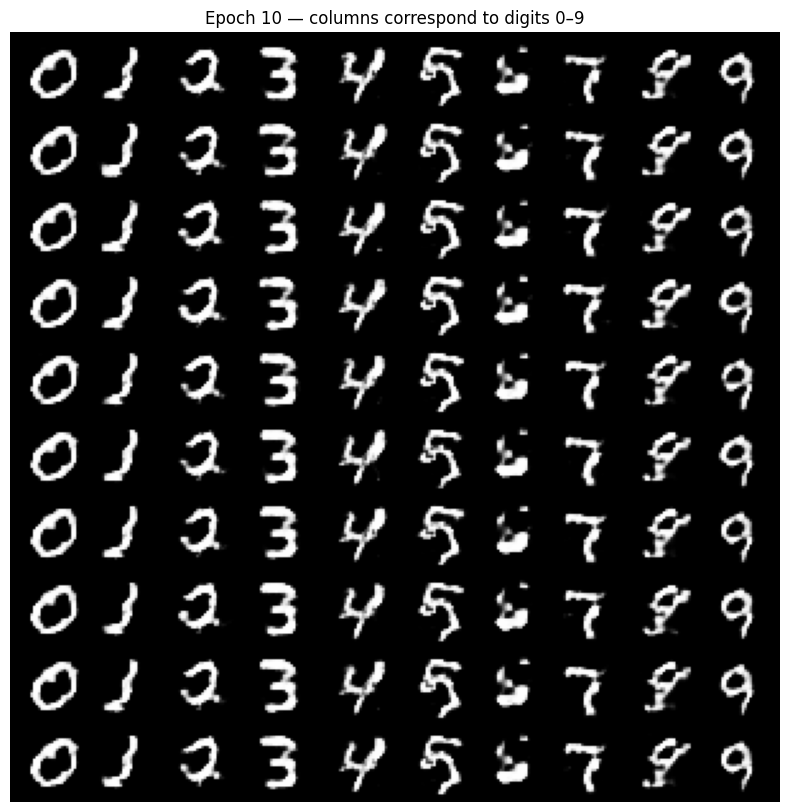

Epoch 11/12 | G loss 0.8182 | D loss 0.6460
Epoch 12/12 | G loss 0.8460 | D loss 0.6363


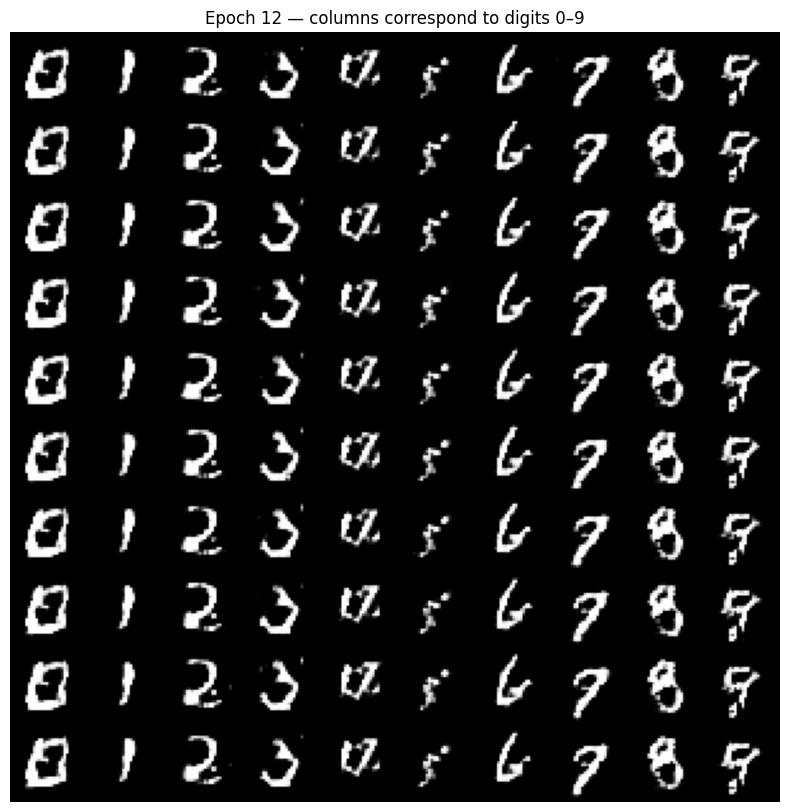

In [4]:
EPOCHS = 12
LR = 0.0002
criterion=nn.BCEWithLogitsLoss()
opt_g=torch.optim.Adam(G.parameters(),lr=LR,betas=(0.5,0.999))
opt_d=torch.optim.Adam(D.parameters(),lr=LR,betas=(0.5,0.999))
fixed_labels=torch.arange(10,device=device).repeat(10)
fixed_noise=torch.randn(100,Z_DIM,device=device)
history={'g':[],'d':[]}
for epoch in range(1,EPOCHS+1):
    G.train();D.train(); g_total=d_total=0.0
    for real,y in loader:
        real,y=real.to(device),y.to(device)
        bs=real.size(0)
        # Discriminator update: real and fake image-label pairs
        opt_d.zero_grad(set_to_none=True)
        noise=torch.randn(bs,Z_DIM,device=device)
        fake=G(noise,y)
        d_real=criterion(D(real,y),torch.ones(bs,device=device))
        d_fake=criterion(D(fake.detach(),y),torch.zeros(bs,device=device))
        d_loss=(d_real+d_fake)/2
        d_loss.backward();opt_d.step()
        # Generator update: fool discriminator with requested class
        opt_g.zero_grad(set_to_none=True)
        fake=G(torch.randn(bs,Z_DIM,device=device),y)
        g_loss=criterion(D(fake,y),torch.ones(bs,device=device))
        g_loss.backward();opt_g.step()
        g_total+=g_loss.item();d_total+=d_loss.item()
    history['g'].append(g_total/len(loader));history['d'].append(d_total/len(loader))
    print(f'Epoch {epoch:02d}/{EPOCHS} | G loss {history["g"][-1]:.4f} | D loss {history["d"][-1]:.4f}')
    if epoch in (1,5,10,EPOCHS):
        G.eval()
        with torch.no_grad(): samples=G(fixed_noise,fixed_labels).cpu()
        save_image((samples+1)/2,OUT/f'epoch_{epoch:02d}.png',nrow=10)
        plt.figure(figsize=(10,10));plt.imshow(make_grid((samples+1)/2,nrow=10).permute(1,2,0));plt.axis('off');plt.title(f'Epoch {epoch} — columns correspond to digits 0–9');plt.show()


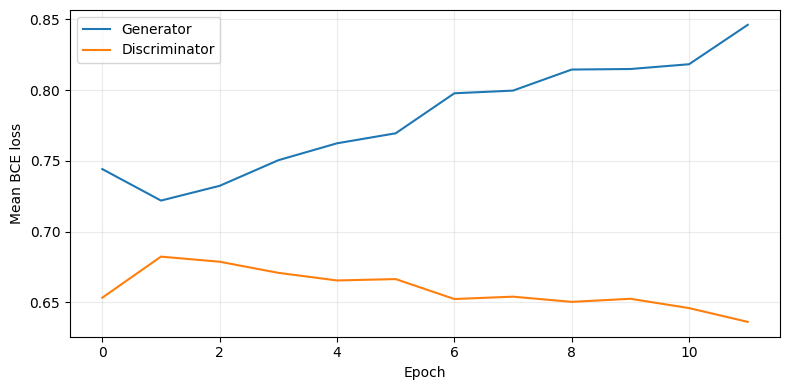

Classifier epoch 1 loss 0.2015
Classifier epoch 2 loss 0.0509
Real MNIST test classifier accuracy: 98.51%
Generated class consistency proxy: 81.00%
Per-digit scores: {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 0.11, 6: 1.0, 7: 0.99, 8: 0.0, 9: 1.0}


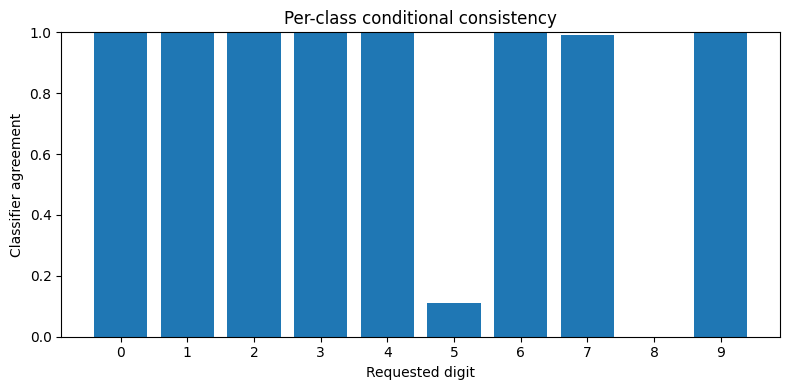

In [5]:
plt.figure(figsize=(8,4))
plt.plot(history['g'],label='Generator');plt.plot(history['d'],label='Discriminator')
plt.xlabel('Epoch');plt.ylabel('Mean BCE loss');plt.legend();plt.grid(alpha=.25);plt.tight_layout()
plt.savefig(OUT/'loss_curves.png',dpi=180);plt.show()

class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Conv2d(1,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Flatten(),nn.Linear(64*7*7,128),nn.ReLU(),nn.Linear(128,10))
    def forward(self,x):return self.net(x)
C=DigitClassifier().to(device)
opt_c=torch.optim.Adam(C.parameters(),lr=0.001)
CLASSIFIER_EPOCHS=2
for epoch in range(CLASSIFIER_EPOCHS):
    C.train();total=0
    for x,y in loader:
        x,y=x.to(device),y.to(device)
        opt_c.zero_grad(set_to_none=True)
        loss=nn.functional.cross_entropy(C(x),y)
        loss.backward();opt_c.step();total+=loss.item()
    print('Classifier epoch',epoch+1,'loss',round(total/len(loader),4))
C.eval();correct=count=0
with torch.no_grad():
    for x,y in test_loader:
        x,y=x.to(device),y.to(device)
        correct+=(C(x).argmax(1)==y).sum().item();count+=len(y)
test_accuracy=correct/count
print(f'Real MNIST test classifier accuracy: {test_accuracy:.2%}')

G.eval();N_PER_CLASS=100
requested=torch.arange(10,device=device).repeat_interleave(N_PER_CLASS)
with torch.no_grad():
    generated=G(torch.randn(len(requested),Z_DIM,device=device),requested)
    predictions=C(generated).argmax(1)
class_scores=[(predictions[requested==digit]==digit).float().mean().item() for digit in range(10)]
consistency=(predictions==requested).float().mean().item()
print(f'Generated class consistency proxy: {consistency:.2%}')
print('Per-digit scores:',{i:round(v,3) for i,v in enumerate(class_scores)})
plt.figure(figsize=(8,4));plt.bar(range(10),class_scores);plt.xticks(range(10));plt.ylim(0,1)
plt.xlabel('Requested digit');plt.ylabel('Classifier agreement');plt.title('Per-class conditional consistency')
plt.tight_layout();plt.savefig(OUT/'class_consistency.png',dpi=180);plt.show()


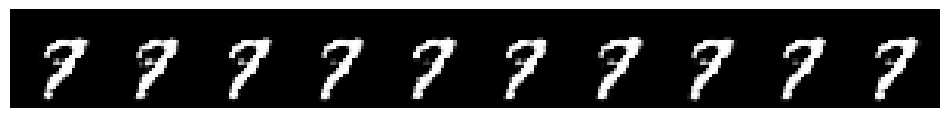

Saved results in /content/cgan_results


In [6]:
def generate_digit(digit, n=10):
    assert 0<=digit<=9 and n>=1
    G.eval()
    with torch.no_grad():
        y=torch.full((n,),digit,device=device,dtype=torch.long)
        x=G(torch.randn(n,Z_DIM,device=device),y).cpu()
    grid=make_grid((x+1)/2,nrow=min(n,10))
    plt.figure(figsize=(min(n,10)*1.2,2));plt.imshow(grid.permute(1,2,0));plt.axis('off');plt.show()
    return x
_ = generate_digit(7,10) # change 7 to any digit 0–9

torch.save({'generator':G.state_dict(),'discriminator':D.state_dict(),
            'classifier':C.state_dict(),'history':history,'seed':SEED,
            'epochs':EPOCHS,'test_accuracy':test_accuracy,
            'class_consistency':consistency,'per_class_consistency':class_scores},OUT/'cgan_checkpoint.pt')
print('Saved results in',OUT)
